# Uygulama 4 – Yapay Sinir Ağlarının Geliştirilmesi ve Kullanılması
**Sena Köse** · YMH451 Yapay Zeka · 2. Hafta

Veri setleri:
- `telefon_fiyat_degisimi.csv` – 2000 telefon, 20 özellik, `price_range` (0–3) sınıfı
- `diyabet.csv` – Pima Indians Diabetes, 768 kayıt, 8 özellik, `Outcome` (0/1) sınıfı

In [1]:
#kütüphanelerin yüklenmesi
import os, random
import numpy as np                      # sayısal diziler
import pandas as pd                     # csv okuma, tablo işlemleri
import matplotlib.pyplot as plt         # grafikler
from sklearn.preprocessing import LabelEncoder, StandardScaler          # etiketleme ve standartlaştırma
from sklearn.model_selection import train_test_split, StratifiedKFold   # eğitim/test ayırma, çapraz doğrulama
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc  # değerlendirme ölçütleri

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # TensorFlow'un bilgi mesajlarını gizle
import tensorflow as tf
from tensorflow.keras.models import Sequential               # katmanları sırayla dizdiğimiz model tipi
from tensorflow.keras.layers import Dense, Dropout, Input    # tam bağlı katman, dropout, girdi katmanı
from tensorflow.keras.utils import to_categorical            # 0-3 etiketlerini one-hot vektöre çevirir
from tensorflow.keras.callbacks import EarlyStopping         # doğrulama kaybı iyileşmeyince eğitimi durdurur

#sonuçların tekrarlanabilir olması için sabit tohum
SEED = 42
def tohum_ayarla(seed=SEED):
    # ağırlıklar rastgele başlatıldığı için tohumu sabitlemezsek her çalıştırmada farklı sonuç çıkar
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
tohum_ayarla()

In [2]:
#eğitim ve doğrulama başarım/kayıp grafiklerini çizen yardımcı fonksiyon (verilen koddaki grafiklerin aynısı)
def grafik_ciz(history, baslik=""):
    # history.history: fit() sırasında her epokta kaydedilen accuracy, val_accuracy, loss, val_loss değerleri
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    # sol grafik: başarım
    ax[0].plot(history.history["accuracy"]); ax[0].plot(history.history["val_accuracy"])
    ax[0].set_title(f"Model Başarımları {baslik}"); ax[0].set_ylabel("Başarım"); ax[0].set_xlabel("Epok sayısı")
    ax[0].legend(["Eğitim", "Test"], loc="upper left")
    # sağ grafik: kayıp
    ax[1].plot(history.history["loss"]); ax[1].plot(history.history["val_loss"])
    ax[1].set_title(f"Model Kayıpları {baslik}"); ax[1].set_ylabel("Kayıp"); ax[1].set_xlabel("Epok sayısı")
    ax[1].legend(["Eğitim", "Test"], loc="upper left")
    plt.tight_layout(); plt.show()

## Soru 1 – Kendi modelimin oluşturulması (10p)
Verilen kodda model `16 → 12 → 4` nöronlu, 150 epok eğitilen bir ağdı. Kendi modelimde şunları değiştirdim:

| | Verilen model | Benim modelim |
|---|---|---|
| Gizli katmanlar | 16, 12 (ReLU) | 64, 32, 16 (ReLU) |
| Aşırı öğrenme önlemi | yok | Dropout (0.3, 0.2) + EarlyStopping |
| Epok | sabit 150 | en fazla 300, doğrulama kaybı 20 epok iyileşmezse durur |
| Test ayrımı | rastgele | `stratify=y` ile sınıf oranları korunur |

Ayrıca verilen kodda `StandardScaler` tüm veriye uygulanıp **sonra** eğitim/test ayrılıyordu; bu, test verisinin ortalama/sapma bilgisinin eğitime sızması demek. Burada önce ayırıp ölçekleyiciyi yalnızca eğitim verisine uyduruyorum.

> **Bu soruda ne yaptım? (basitçe)**
>
> Elimde 2000 telefonun bilgileri var: RAM'i, bataryası, kamerası gibi. Her telefonun da ucuz, orta, pahalı ya da çok pahalı olduğu yazıyor.
>
> Bilgisayara bir "beyin" (yapay sinir ağı) yaptım ve ona bu telefonları gösterip fiyatı tahmin etmeyi öğrettim. Telefonların çoğunu ders çalışması için verdim, bir kısmını sınav için sakladım.
>
> Sonra sınav yaptım: beyin hiç görmediği 400 telefonun 366'sının fiyatını doğru bildi (%91.5).

In [3]:
#verisetinin yüklenmesi
veri = pd.read_csv("telefon_fiyat_degisimi.csv")   # 2000 satır, 21 sütun (20 özellik + price_range)
print(veri.shape)
veri.head()                                          # ilk 5 satıra göz at

(2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [4]:
#sınıf sayısının belirlenmesi
label_encoder = LabelEncoder().fit(veri.price_range)   # price_range içindeki farklı değerleri öğren
labels = label_encoder.transform(veri.price_range)     # her satırı 0,1,2,3 sınıf numarasına çevir
classes = list(label_encoder.classes_)                 # sınıf listesi: [0, 1, 2, 3]
print("Sınıflar:", classes)
print(veri.price_range.value_counts().sort_index())    # her sınıftan 500 örnek var → veri dengeli

#girdi ve çıktı verilerinin hazırlanması
X = veri.drop(["price_range"], axis=1).values   # girdiler: price_range dışındaki 20 sütun
y = labels                                      # çıktı: fiyat sınıfı

#eğitim ve test verilerinin hazırlanması (sınıf oranları korunarak)
# test_size=0.2 → %80 eğitim (1600), %20 test (400); stratify=y → her sınıf test setinde de %25
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

#verilerin standartlaştırılması (yalnızca eğitim verisine fit)
# her sütunu ortalama 0, standart sapma 1 olacak şekilde ölçekler; ram (~4000) ile wifi (0/1) aynı ölçeğe gelir
sc = StandardScaler()
X_train = sc.fit_transform(X_train)   # ortalama/sapmayı eğitim verisinden öğren ve uygula
X_test = sc.transform(X_test)         # teste aynı dönüşümü uygula (testten bir şey öğrenme → sızıntı yok)

#çıktı değerlerinin kategorileştirilmesi
# softmax çıkışı 4 değer verdiği için etiketi de 4 elemanlı vektöre çeviriyoruz: 2 → [0, 0, 1, 0]
y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

Sınıflar: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


In [5]:
#modelin oluşturulması
def benim_modelim(girdi_sayisi, sinif_sayisi=4):
    model = Sequential([
        Input(shape=(girdi_sayisi,)),          # girdi katmanı: özellik sayısı kadar nöron (20)
        Dense(64, activation="relu"),          # 1. gizli katman: 64 nöron, ReLU = max(0, x)
        Dropout(0.3),                          # eğitimde nöronların %30'unu rastgele kapat → ezberlemeyi azaltır
        Dense(32, activation="relu"),          # 2. gizli katman: 32 nöron
        Dropout(0.2),                          # %20 dropout
        Dense(16, activation="relu"),          # 3. gizli katman: 16 nöron
        Dense(sinif_sayisi, activation="softmax"),  # çıkış: 4 nöron, softmax → 4 sınıfın olasılıkları (toplamı 1)
    ])
    #modelin derlenmesi
    # categorical_crossentropy: çok sınıflı problemlerde kullanılan kayıp fonksiyonu
    # adam: ağırlıkları geri yayılımla güncelleyen optimizasyon algoritması
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model

tohum_ayarla()
model = benim_modelim(X_train.shape[1])   # X_train.shape[1] = 20 özellik
model.summary()                           # katmanları ve öğrenilecek parametre (ağırlık) sayısını göster

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,020 (15.70 KB)

 Trainable params: 4,020 (15.70 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
#modelin eğitilmesi
# val_loss 20 epok boyunca iyileşmezse dur ve en iyi epoktaki ağırlıklara geri dön
erken_durdurma = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
history = model.fit(X_train, y_train_cat, validation_data=(X_test, y_test_cat),   # her epok sonunda test verisiyle de ölç
                    epochs=300, batch_size=32,      # en fazla 300 epok; ağırlıklar her 32 örnekte bir güncellenir
                    callbacks=[erken_durdurma], verbose=0)
print("Eğitim", len(history.history["loss"]), "epokta durdu.")

# predict 4 olasılık döndürür; argmax en yüksek olasılıklı sınıfı seçer
y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
s1_acc = accuracy_score(y_test, y_pred)   # doğru tahmin sayısı / toplam
print(f"Test başarımı: {s1_acc:.4f}")
print(classification_report(y_test, y_pred, digits=3))   # her sınıf için precision, recall, f1

Eğitim 53 epokta durdu.
Test başarımı: 0.9150
              precision    recall  f1-score   support

           0      0.933     0.970     0.951       100
           1      0.916     0.870     0.892       100
           2      0.913     0.840     0.875       100
           3      0.899     0.980     0.938       100

    accuracy                          0.915       400
   macro avg      0.915     0.915     0.914       400
weighted avg      0.915     0.915     0.914       400



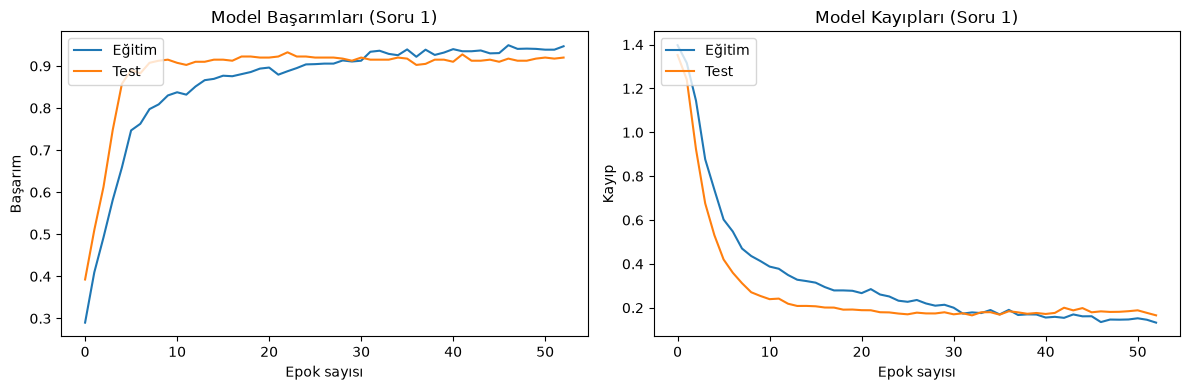

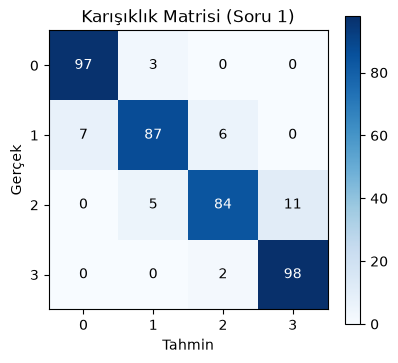

In [7]:
#eğitim ve doğrulama başarımlarının gösterilmesi
grafik_ciz(history, "(Soru 1)")

#karışıklık matrisi: satır = gerçek sınıf, sütun = tahmin; köşegen doğru tahminler
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4.5, 4))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
for i in range(4):
    for j in range(4):
        # her hücreye sayıyı yaz (koyu hücrede beyaz, açık hücrede siyah)
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
plt.xticks(range(4), classes); plt.yticks(range(4), classes)
plt.xlabel("Tahmin"); plt.ylabel("Gerçek"); plt.title("Karışıklık Matrisi (Soru 1)")
plt.show()

**Yorum (Soru 1):** Model doğrulama kaybı 20 epok boyunca iyileşmeyince 53. epokta durdu ve en iyi ağırlıklara geri döndü; test başarımı **%91.5**. Karışıklık matrisinde hatalar neredeyse yalnızca **komşu sınıflar** arasında (1↔2 gibi). 0 ile 3 karıştırılmıyor, çünkü fiyat aralıkları sıralı ve uç sınıflar birbirinden çok farklı. En zor sınıflar orta segment (1 ve 2), f1 ≈ 0.88–0.89.

## Soru 2 – Çapraz doğrulama ile başarımın değerlendirilmesi (30p)
Tek bir eğitim/test ayrımında başarım, hangi örneklerin teste düştüğüne bağlıdır (şanslı ya da şanssız bir bölme). **k-katlı çapraz doğrulamada** veri k parçaya bölünür; her turda bir parça test, kalan k−1 parça eğitim olur. k farklı başarımın ortalaması ve standart sapması modelin genelleme yeteneğini çok daha güvenilir gösterir.

- `StratifiedKFold(n_splits=5, shuffle=True)` – her katta 4 sınıfın oranı (%25) korunur.
- Her katta **sıfırdan yeni bir model** kurulur (önceki katın ağırlıkları taşınmaz).
- `StandardScaler` her katta yalnızca o katın eğitim verisine uydurulur (veri sızıntısı yok).
- Her model için hem verilen model (16-12-4) hem de benim modelim çalıştırılır ki karşılaştırma yapılabilsin.

> **Bu soruda ne yaptım? (basitçe)**
>
> Tek bir sınav şans eseri kolay ya da zor gelmiş olabilir. O yüzden 5 farklı sınav yaptım.
>
> Telefonları 5 gruba ayırdım. Her seferinde 4 grupla ders çalıştırdım, kalan 1 grupla sınav yaptım. Bunu 5 kere tekrarladım, böylece her telefon bir kere sınav sorusu oldu.
>
> 5 sınavın ortalamasını aldım: benim beynim %92.5, hocanın verdiği beyin %92 aldı. Notlar sınavdan sınava çok değişmedi, yani beyin şansla değil gerçekten öğrenmiş.

In [8]:
#verilen koddaki model (karşılaştırma için): 16 → 12 → 4
def verilen_model(girdi_sayisi, sinif_sayisi=4):
    model = Sequential([
        Input(shape=(girdi_sayisi,)),
        Dense(16, activation="relu"),
        Dense(12, activation="relu"),
        Dense(sinif_sayisi, activation="softmax"),
    ])
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model

def capraz_dogrulama(X, y, model_fn, k=5, epochs=150, erken=False):
    # veriyi k kata böl; shuffle=True → bölmeden önce karıştır, stratified → her katta sınıf oranları aynı
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    skorlar = []
    for kat, (egt, tst) in enumerate(skf.split(X, y), 1):   # egt/tst: o turdaki eğitim ve test satır numaraları
        tohum_ayarla(SEED + kat)
        sc = StandardScaler().fit(X[egt])                     # ölçekleyiciyi sadece bu turun eğitim verisinden öğren
        Xe, Xt = sc.transform(X[egt]), sc.transform(X[tst])
        ye, yt = to_categorical(y[egt], 4), to_categorical(y[tst], 4)
        model = model_fn(X.shape[1])                          # her turda sıfırdan yeni model (önceki tur bilgisi taşınmaz)
        cb = [EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)] if erken else []
        model.fit(Xe, ye, validation_data=(Xt, yt), epochs=epochs, batch_size=32, callbacks=cb, verbose=0)
        acc = accuracy_score(y[tst], model.predict(Xt, verbose=0).argmax(axis=1))   # bu katın test başarımı
        skorlar.append(acc)
        print(f"  Kat {kat}: başarım = {acc:.4f}")
    skorlar = np.array(skorlar)
    # ortalama: modelin beklenen başarımı; std: bölmeye göre ne kadar değiştiği (küçükse model kararlı)
    print(f"  Ortalama = {skorlar.mean():.4f} ± {skorlar.std():.4f}")
    return skorlar

X_tum = veri.drop(["price_range"], axis=1).values   # ölçeklenmemiş ham veri (ölçekleme fonksiyon içinde yapılıyor)
y_tum = labels

print("Verilen model (16-12-4, 150 epok):")
cv_verilen = capraz_dogrulama(X_tum, y_tum, verilen_model, epochs=150)
print("\nBenim modelim (64-32-16-4, Dropout, EarlyStopping):")
cv_benim = capraz_dogrulama(X_tum, y_tum, benim_modelim, epochs=300, erken=True)

Verilen model (16-12-4, 150 epok):


  Kat 1: başarım = 0.9225


  Kat 2: başarım = 0.9175


  Kat 3: başarım = 0.9025


  Kat 4: başarım = 0.9275


...

  Kat 1: başarım = 0.9300


  Kat 2: başarım = 0.9400


  Kat 3: başarım = 0.9150


  Kat 4: başarım = 0.9250


  Kat 5: başarım = 0.9150
  Ortalama = 0.9250 ± 0.0095


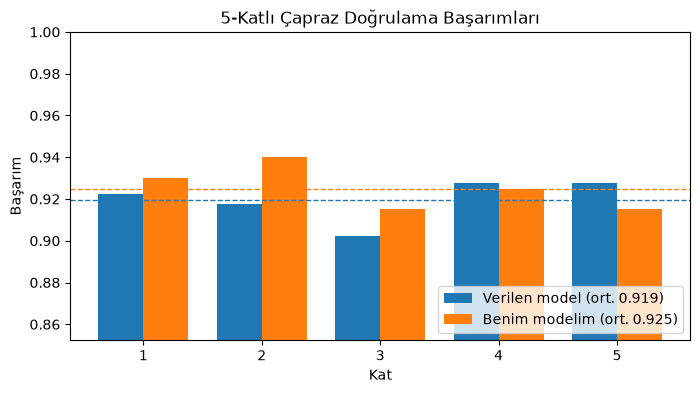

,Kat 1,Kat 2,Kat 3,Kat 4,Kat 5,Ortalama,StdSapma
Verilen model,0.9225,0.9175,0.9025,0.9275,0.9275,0.9195,0.0093
Benim modelim,0.9300,0.9400,0.9150,0.9250,0.9150,0.9250,0.0095


In [9]:
#katlara göre başarımların gösterilmesi: her kat için iki modelin sütunu yan yana
katlar = np.arange(1, 6); w = 0.38
plt.figure(figsize=(8, 4))
plt.bar(katlar - w/2, cv_verilen, w, label=f"Verilen model (ort. {cv_verilen.mean():.3f})")
plt.bar(katlar + w/2, cv_benim, w, label=f"Benim modelim (ort. {cv_benim.mean():.3f})")
# kesikli çizgiler: iki modelin ortalama başarımı
plt.axhline(cv_verilen.mean(), color="C0", ls="--", lw=1); plt.axhline(cv_benim.mean(), color="C1", ls="--", lw=1)
lo = min(cv_verilen.min(), cv_benim.min())
plt.ylim(max(0, lo - 0.05), 1.0)
plt.xlabel("Kat"); plt.ylabel("Başarım"); plt.title("5-Katlı Çapraz Doğrulama Başarımları")
plt.legend(loc="lower right"); plt.show()

#sonuç tablosu: her katın başarımı + ortalama + standart sapma
pd.DataFrame({"Verilen model": cv_verilen, "Benim modelim": cv_benim}, index=[f"Kat {i}" for i in katlar]).T.assign(
    Ortalama=lambda d: d.mean(axis=1), StdSapma=lambda d: d.iloc[:, :5].std(axis=1, ddof=0)).round(4)

**Yorum (Soru 2):** 5-katlı çapraz doğrulamada verilen model **%91.95 ± 0.93**, benim modelim **%92.50 ± 0.95** ortalama başarıma ulaştı. Benim modelim 5 katın 3'ünde daha iyi; fark küçük (~0.5 puan) ve standart sapmalar içinde kalıyor. Yani daha büyük ağ + Dropout belirgin bir sıçrama yapmıyor, ama EarlyStopping sayesinde 150 sabit epok yerine ortalama çok daha az epokta aynı seviyeye geliyor.

Katlar arası fark (%90.25 – %94.00) tek bir eğitim/test bölmesinin ne kadar yanıltıcı olabileceğini gösteriyor: Soru 1'deki %91.5 tek bir bölmenin sonucuydu, gerçek beklenen başarım ≈ %92.5'tir. Düşük standart sapma (< %1) modelin veri bölünmesine karşı **kararlı** olduğunu gösterir.

## Soru 3 – "blue", "fc", "int_memory", "ram" ve "wifi" çıkarılarak sınıflandırma (10p)
Aynı model (benim modelim) ve aynı 5-katlı çapraz doğrulama, 20 yerine kalan **15 özellik** ile tekrarlanır. Böylece fark yalnızca çıkarılan özelliklerden kaynaklanır.

> **Bu soruda ne yaptım? (basitçe)**
>
> Telefon bilgilerinden 5 tanesini sildim: bluetooth, ön kamera, hafıza, RAM ve wifi. Sonra beyne aynı şekilde tekrar ders çalıştırıp sınav yaptım.
>
> Notu %92'den %32'ye düştü. Neredeyse göz kapalı tahmin etmek kadar kötü (4 şıktan rastgele seçmek %25 eder).
>
> Sebebi RAM: telefonun fiyatını en çok RAM'i belli ediyor. RAM'i elinden alınca beyin fiyatı tahmin edemez hale geldi.

In [10]:
cikarilacak = ["blue", "fc", "int_memory", "ram", "wifi"]
veri_15 = veri.drop(cikarilacak + ["price_range"], axis=1)   # 5 özelliği ve çıktı sütununu at
print("Kalan özellik sayısı:", veri_15.shape[1])
print(list(veri_15.columns))

X_15 = veri_15.values
print("\nBenim modelim – 15 özellik:")
# Soru 2'deki fonksiyonun aynısı; model girdi sayısını X.shape[1]'den otomatik 15 alır
cv_15 = capraz_dogrulama(X_15, y_tum, benim_modelim, epochs=300, erken=True)

Kalan özellik sayısı: 15
['battery_power', 'clock_speed', 'dual_sim', 'four_g', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen']

Benim modelim – 15 özellik:


  Kat 1: başarım = 0.3100


  Kat 2: başarım = 0.3275


  Kat 3: başarım = 0.3250


  Kat 4: başarım = 0.2875


  Kat 5: başarım = 0.3400
  Ortalama = 0.3180 ± 0.0180


Test başarımı (15 özellik): 0.3550   |   20 özellik ile: 0.9150


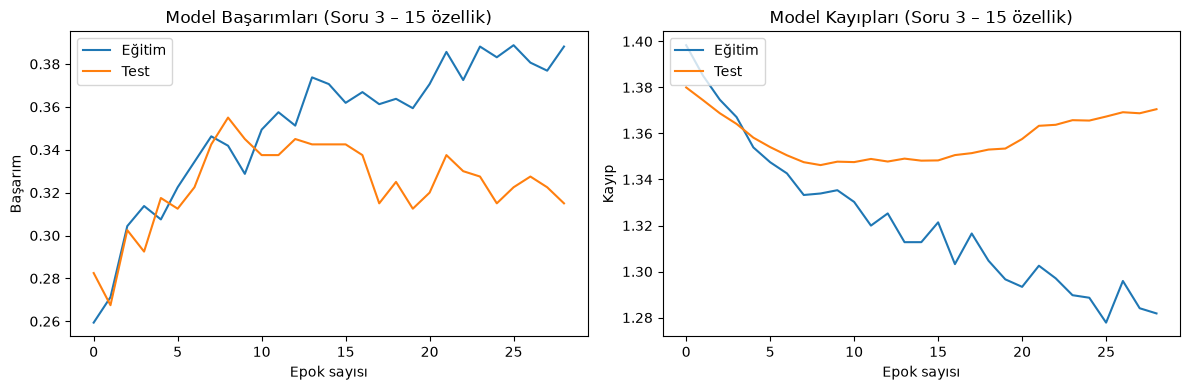

In [11]:
#tek bölme üzerinde de eğitip grafiklerini çizelim (Soru 1'deki adımların 15 özellikli hali)
X_train15, X_test15, y_train15, y_test15 = train_test_split(X_15, y_tum, test_size=0.2, stratify=y_tum, random_state=SEED)
sc15 = StandardScaler().fit(X_train15)
X_train15, X_test15 = sc15.transform(X_train15), sc15.transform(X_test15)
tohum_ayarla()
model15 = benim_modelim(15)   # girdi katmanı artık 15 nöron
history15 = model15.fit(X_train15, to_categorical(y_train15, 4), validation_data=(X_test15, to_categorical(y_test15, 4)),
                        epochs=300, batch_size=32, callbacks=[EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)], verbose=0)
s3_acc = accuracy_score(y_test15, model15.predict(X_test15, verbose=0).argmax(axis=1))
print(f"Test başarımı (15 özellik): {s3_acc:.4f}   |   20 özellik ile: {s1_acc:.4f}")
grafik_ciz(history15, "(Soru 3 – 15 özellik)")

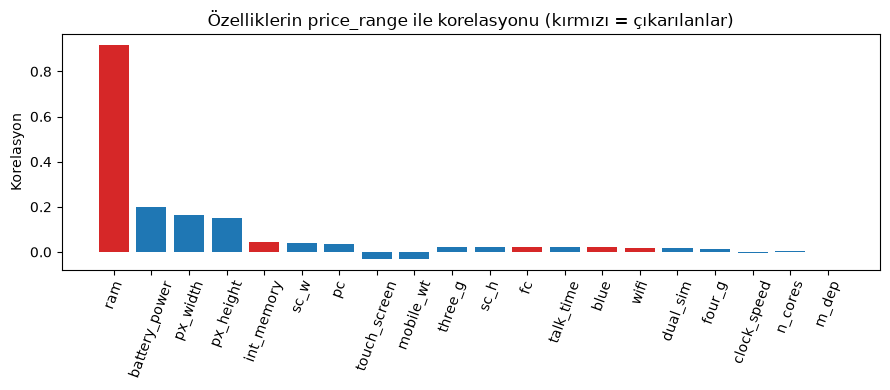

blue          0.021
fc            0.022
int_memory    0.044
ram           0.917
wifi          0.019
Name: price_range, dtype: float64


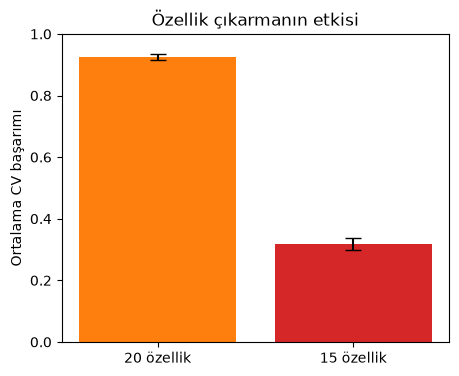

In [12]:
#hangi özelliğin etkisi büyük? her özelliğin price_range ile korelasyonu (-1 ile 1 arası; 0'a yakın = ilişki yok)
kor = veri.corr()["price_range"].drop("price_range").sort_values(key=abs, ascending=False)
renk = ["C3" if c in cikarilacak else "C0" for c in kor.index]   # çıkarılan özellikler kırmızı
plt.figure(figsize=(9, 4))
plt.bar(kor.index, kor.values, color=renk)
plt.xticks(rotation=70); plt.ylabel("Korelasyon"); plt.title("Özelliklerin price_range ile korelasyonu (kırmızı = çıkarılanlar)")
plt.tight_layout(); plt.show()
print(kor.loc[cikarilacak].round(3))   # çıkarılan 5 özelliğin korelasyonları

#20 ve 15 özellikle ortalama CV başarımı (hata çubukları = standart sapma)
plt.figure(figsize=(5, 4))
plt.bar(["20 özellik", "15 özellik"], [cv_benim.mean(), cv_15.mean()], yerr=[cv_benim.std(), cv_15.std()], capsize=6, color=["C1", "C3"])
plt.ylim(0, 1); plt.ylabel("Ortalama CV başarımı"); plt.title("Özellik çıkarmanın etkisi")
plt.show()

**Yorum (Soru 3):** 5 özellik çıkarıldığında ortalama CV başarımı **%92.5'ten %31.8'e** düştü. 4 sınıflı dengeli bir problemde rastgele tahmin %25 olduğu için model artık neredeyse tahmin yapamıyor. Eğitim grafiğinde de doğrulama kaybı ilk epoklardan sonra yükselmeye başlıyor; model yalnızca gürültüyü ezberliyor.

Nedeni korelasyon grafiğinde açık: çıkarılanlardan **`ram`'in price_range ile korelasyonu 0.917**, diğer dördünün (blue, fc, int_memory, wifi) ise 0.05'in altında. Yani düşüşün neredeyse tamamı `ram`'den geliyor; diğer dört özellik zaten fiyat hakkında çok az bilgi taşıyordu. Kalan 15 özellik içinde en güçlüleri (battery_power, px_height, px_width) bile yalnızca 0.15–0.20 korelasyona sahip. Bu da özellik seçiminin önemini gösteriyor: tek bir baskın özelliği kaybetmek, modeli tamamen etkisiz bırakabilir.

## Soru 4 – Diyabet veri seti ile YSA modeli (20p)
Pima Indians Diabetes verisi: 768 kişi, 8 klinik özellik, `Outcome` = 1 ise diyabet. Bu bir **ikili** sınıflandırma olduğu için çıkış katmanı tek nöron + `sigmoid`, kayıp fonksiyonu `binary_crossentropy`.

**Ön işleme:** Glucose, BloodPressure, SkinThickness, Insulin ve BMI sütunlarında `0` değerleri biyolojik olarak imkânsız; bunlar aslında eksik veri. Bu sıfırları eğitim verisinin medyanı ile dolduruyorum.

> **Bu soruda ne yaptım? (basitçe)**
>
> Bu sefer 768 kişinin sağlık bilgileri var: kan şekeri, kilo, yaş gibi. Her kişinin diyabet olup olmadığı da yazıyor.
>
> Bazı kişilerin kan şekeri 0 yazıyordu, bu imkânsız; demek ki ölçülmemiş. Bu boşlukları diğer insanların ortadaki (medyan) değeriyle doldurdum.
>
> Yeni bir beyin yapıp "bu kişi diyabet mi değil mi?" sorusunu öğrettim. Her ders turundan sonra hem çalıştığı sorulardaki hem de hiç görmediği sorulardaki notunu kaydedip grafiğe çizdim.
>
> Grafikte şunu gördüm: beyin bir süre sonra ezberlemeye başlıyor. Çalıştığı sorularda notu artıyor (%83) ama yeni sorularda %71'de kalıyor.

In [13]:
diyabet = pd.read_csv("diyabet.csv")   # 768 satır, 8 özellik + Outcome
print(diyabet.shape)
# sınıf dağılımı: 500 sağlıklı, 268 diyabet → veri dengesiz
print(diyabet.Outcome.value_counts().rename({0: "Sağlıklı (0)", 1: "Diyabet (1)"}))
#0 değeri alamayacak sütunlar (kan şekeri, tansiyon vb. 0 olamaz → eksik veri)
sifir_sutunlar = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("\nSıfır (eksik) değer sayıları:")
print((diyabet[sifir_sutunlar] == 0).sum())
diyabet.describe().round(2)   # her sütunun ortalama, min, max vb. özet istatistikleri

(768, 9)
Outcome
Sağlıklı (0)    500
Diyabet (1)     268
Name: count, dtype: int64

Sıfır (eksik) değer sayıları:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


In [14]:
Xd = diyabet.drop(["Outcome"], axis=1).copy()   # girdiler: 8 klinik özellik
yd = diyabet["Outcome"].values                  # çıktı: 0 = sağlıklı, 1 = diyabet

#eğitim / test ayrımı (%80 / %20, sınıf oranları korunarak)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.2, stratify=yd, random_state=SEED)

#sıfırları eğitim medyanıyla doldurma (medyan, uç değerlerden ortalamaya göre daha az etkilenir)
for s in sifir_sutunlar:
    medyan = Xd_train.loc[Xd_train[s] != 0, s].median()   # sıfır olmayan eğitim değerlerinin medyanı
    Xd_train[s] = Xd_train[s].replace(0, medyan)
    Xd_test[s] = Xd_test[s].replace(0, medyan)            # teste de eğitimden hesaplanan medyanı uygula

#standartlaştırma (yine yalnızca eğitim verisine fit)
scd = StandardScaler().fit(Xd_train)
Xd_train, Xd_test = scd.transform(Xd_train), scd.transform(Xd_test)

#modelin oluşturulması
tohum_ayarla()
model_d = Sequential([
    Input(shape=(8,)),                 # 8 girdi nöronu
    Dense(16, activation="relu"),      # 1. gizli katman
    Dropout(0.2),                      # aşırı öğrenmeyi azaltmak için
    Dense(8, activation="relu"),       # 2. gizli katman
    Dense(1, activation="sigmoid"),    # tek çıkış: sigmoid → diyabet olma olasılığı (0–1)
])
# ikili sınıflandırma olduğu için binary_crossentropy; etiketleri one-hot yapmaya gerek yok
model_d.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model_d.summary()

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_63 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

Son epok  → Eğitim başarımı: 0.8274  Doğrulama başarımı: 0.7078
Son epok  → Eğitim kaybı:    0.3885  Doğrulama kaybı:    0.5593
En düşük doğrulama kaybı epok 18: kayıp=0.5260, başarım=0.7013


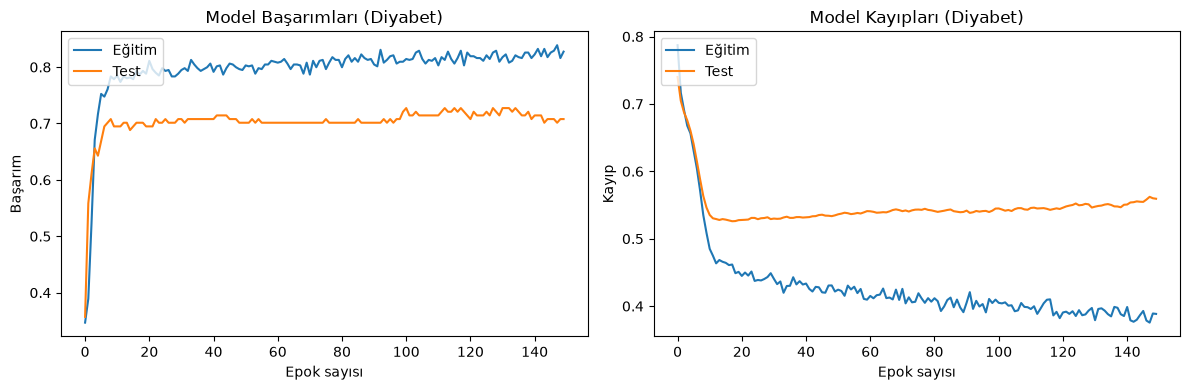

In [15]:
#modelin eğitilmesi (eğitim ve doğrulama başarım/kayıplarının kaydı)
# validation_data verildiği için her epokta hem eğitim hem doğrulama başarım/kaybı history'ye yazılır
history_d = model_d.fit(Xd_train, yd_train, validation_data=(Xd_test, yd_test),
                        epochs=150, batch_size=16, verbose=0)

h = history_d.history
print(f"Son epok  → Eğitim başarımı: {h['accuracy'][-1]:.4f}  Doğrulama başarımı: {h['val_accuracy'][-1]:.4f}")
print(f"Son epok  → Eğitim kaybı:    {h['loss'][-1]:.4f}  Doğrulama kaybı:    {h['val_loss'][-1]:.4f}")
en_iyi = int(np.argmin(h["val_loss"]))   # doğrulama kaybının en düşük olduğu epok
print(f"En düşük doğrulama kaybı epok {en_iyi+1}: kayıp={h['val_loss'][en_iyi]:.4f}, başarım={h['val_accuracy'][en_iyi]:.4f}")

#eğitim ve doğrulama başarım/kayıplarının grafikte gösterilmesi
grafik_ciz(history_d, "(Diyabet)")

In [16]:
yd_prob = model_d.predict(Xd_test, verbose=0).ravel()   # her test hastası için diyabet olasılığı
yd_pred = (yd_prob >= 0.5).astype(int)                  # olasılık 0.5 ve üzeriyse "diyabet" de
print(f"Test başarımı: {accuracy_score(yd_test, yd_pred):.4f}")
print(classification_report(yd_test, yd_pred, target_names=["Sağlıklı", "Diyabet"], digits=3))
# karışıklık matrisi: [[doğru sağlıklı, yanlış alarm], [kaçırılan diyabet, doğru diyabet]]
print("Karışıklık matrisi:\n", confusion_matrix(yd_test, yd_pred))

Test başarımı: 0.7078
              precision    recall  f1-score   support

    Sağlıklı      0.757     0.810     0.783       100
     Diyabet      0.596     0.519     0.554        54

    accuracy                          0.708       154
   macro avg      0.676     0.664     0.669       154
weighted avg      0.700     0.708     0.703       154

Karışıklık matrisi:
 [[81 19]
 [26 28]]


**Yorum (Soru 4):** Grafiklerde **aşırı öğrenme (overfitting)** açıkça görülüyor: eğitim kaybı 150 epok boyunca sürekli düşerken (0.39), doğrulama kaybı **18. epokta en düşük değerine (0.526)** ulaşıp sonra yükseliyor (0.559). Aynı şekilde eğitim başarımı %82.7'ye çıkarken doğrulama başarımı %70–72 bandında kalıyor. Daha uzun eğitim eğitim verisini ezberletiyor ama yeni hastalara genellemeyi iyileştirmiyor; burada EarlyStopping (≈20 epok) kullanmak daha doğru olurdu.

Test başarımı %70.8. Veri dengesiz (500 sağlıklı / 268 diyabet) olduğundan model sağlıklı sınıfında iyi (recall 0.81), diyabet sınıfında zayıf (recall 0.52): 54 diyabetli hastanın 26'sını kaçırıyor. Tıbbi bir problemde bu yanlış negatifler en maliyetli hata türüdür; bu yüzden yalnızca başarıma bakmak yetmez, Soru 5'teki ROC analizi gerekir.

## Soru 5 – ROC eğrisi (30p)
ROC eğrisi, sınıflandırıcının karar eşiği 1'den 0'a kaydırılırken her eşik için **Doğru Pozitif Oranı** (TPR = TP / (TP+FN), duyarlılık) ile **Yanlış Pozitif Oranını** (FPR = FP / (FP+TN)) çizer. Bu yüzden modelin sınıf etiketi değil, sigmoid çıkışındaki **olasılık** değeri kullanılır.

- Köşegen (FPR = TPR) rastgele tahmin eden bir modeldir, AUC = 0.5.
- Eğri sol üst köşeye ne kadar yakınsa model o kadar iyidir; ideal modelde AUC = 1.
- AUC: rastgele seçilen bir diyabetli hastaya, rastgele seçilen sağlıklı birinden daha yüksek olasılık verme ihtimali.

> **Bu soruda ne yaptım? (basitçe)**
>
> Beyin her kişi için "bu kişinin diyabet olma ihtimali %70" gibi bir sayı söylüyor. Biz de "%50'nin üstüyse diyabet de" diye bir sınır koymuştuk.
>
> ROC eğrisi, bu sınırı yukarı aşağı oynattığımızda ne olduğunu gösteren bir çizgi: kaç hastayı doğru yakalıyoruz, kaç sağlam kişiye yanlışlıkla "hasta" diyoruz.
>
> Çizgi sol üst köşeye ne kadar yakınsa beyin o kadar iyi. Bizim beynin puanı (AUC) 0.80 çıktı. 1 mükemmel, 0.5 yazı-tura atmak demek; yani beyin iyi ayırt ediyor.
>
> Bir de şunu buldum: sınırı %50 yerine %19 yapınca kaçırdığımız hasta sayısı 26'dan 7'ye iniyor. Hastalıkta kimseyi kaçırmamak daha önemli olduğu için bu sınır daha iyi.

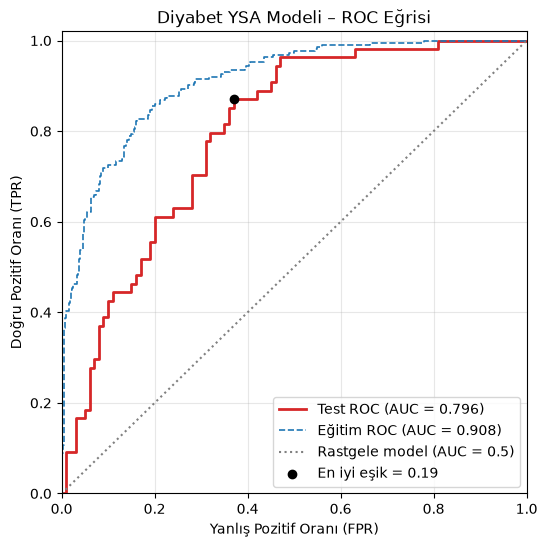

Test AUC = 0.7963  |  Eğitim AUC = 0.9083
Youden J ile en iyi eşik: 0.194  →  TPR = 0.870, FPR = 0.370
Bu eşikte başarım: 0.7143
Karışıklık matrisi (yeni eşik):
 [[63 37]
 [ 7 47]]


In [17]:
#test verisi için ROC: her eşik değerinde FPR ve TPR hesaplanır
fpr, tpr, esikler = roc_curve(yd_test, yd_prob)   # etiket değil, olasılıklar (yd_prob) kullanılıyor
roc_auc = auc(fpr, tpr)                           # eğrinin altında kalan alan

#eğitim verisi üzerindeki ROC (aşırı öğrenme kontrolü için)
fpr_e, tpr_e, _ = roc_curve(yd_train, model_d.predict(Xd_train, verbose=0).ravel())
auc_e = auc(fpr_e, tpr_e)

#Youden J istatistiği ile en iyi eşik: TPR - FPR farkının en büyük olduğu nokta
j = int(np.argmax(tpr - fpr))

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, lw=2, color="C3", label=f"Test ROC (AUC = {roc_auc:.3f})")
plt.plot(fpr_e, tpr_e, lw=1.2, color="C0", ls="--", label=f"Eğitim ROC (AUC = {auc_e:.3f})")
plt.plot([0, 1], [0, 1], color="gray", ls=":", label="Rastgele model (AUC = 0.5)")   # köşegen
plt.scatter(fpr[j], tpr[j], color="black", zorder=5, label=f"En iyi eşik = {esikler[j]:.2f}")
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.xlabel("Yanlış Pozitif Oranı (FPR)"); plt.ylabel("Doğru Pozitif Oranı (TPR)")
plt.title("Diyabet YSA Modeli – ROC Eğrisi"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.show()

print(f"Test AUC = {roc_auc:.4f}  |  Eğitim AUC = {auc_e:.4f}")
print(f"Youden J ile en iyi eşik: {esikler[j]:.3f}  →  TPR = {tpr[j]:.3f}, FPR = {fpr[j]:.3f}")
#0.5 yerine bulunan eşikle tekrar sınıflandır ve sonucu karşılaştır
yd_pred_j = (yd_prob >= esikler[j]).astype(int)
print(f"Bu eşikte başarım: {accuracy_score(yd_test, yd_pred_j):.4f}")
print("Karışıklık matrisi (yeni eşik):\n", confusion_matrix(yd_test, yd_pred_j))

**Yorum (Soru 5):** Test verisinde **AUC = 0.796**. Model, rastgele seçilen bir diyabetli hastaya sağlıklı birinden daha yüksek risk vermeyi yaklaşık %80 olasılıkla başarıyor; rastgele modelin (0.5) belirgin şekilde üzerinde, "kabul edilebilir/iyi" ayırt edicilik seviyesinde. Eğitim AUC'u (0.908) ile test AUC'u arasındaki fark, Soru 4'te görülen aşırı öğrenmeyi doğruluyor.

ROC eğrisi varsayılan 0.5 eşiğinin bu problem için iyi olmadığını da gösteriyor. Youden J (TPR − FPR'yi en büyük yapan nokta) ile bulunan **0.19 eşiğinde** duyarlılık 0.52'den **0.87'ye** çıkıyor: kaçırılan diyabetli sayısı 26'dan 7'ye iniyor, genel başarım da düşmüyor (%71.4). Bedeli yanlış alarmların 19'dan 37'ye çıkması. Tarama testlerinde hastayı kaçırmak yanlış alarmdan daha pahalı olduğu için bu eşik daha uygun bir tercih.